# Combine Break Measures and Rookie NFL Performance

**NFL Big Data Bowl 2027, Open Track.** This notebook reproduces every result in the writeup, from the raw Kaggle files to the final tables and figures. It runs top to bottom in about a few minutes.

**Question.** Do movement measures from the 10 Hz Combine tracking (cut angle, speed kept through a break) predict how prospects perform in their rookie regular season?

**Short answer.** No robust link for wide receivers or defensive backs. One lead (dagger route, speed retained) did not survive a pre-specified check and is reported as withdrawn.

## 1. Setup
Set `DATA` to the folder containing the Kaggle CSVs.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

DATA = "/kaggle/input/nfl-big-data-bowl-2027"   # change if running elsewhere
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load outcomes
Rookie season is the season matching the draft year. Only regular-season games are used.

In [2]:
pl = pd.read_csv(f"{DATA}/players.csv")
gm = pd.read_csv(f"{DATA}/games.csv", usecols=["game_id", "season", "season_type"])
pp = pd.read_csv(f"{DATA}/player_play.csv",
                 usecols=["game_id", "nfl_id", "route_ran", "target",
                          "separation_at_pass_forward", "coverage_assignment", "pass_result"])

# Receiver outcome: mean separation on targets, rookie regular season
tgt = (pp[(pp.target == 1) & pp.separation_at_pass_forward.notna()]
       .merge(gm, on="game_id").merge(pl[["nfl_id", "draft_year"]], on="nfl_id"))
tgt = tgt[(tgt.season == tgt.draft_year) & (tgt.season_type == "REG")]
print("receiver target rows:", len(tgt))

receiver target rows: 3731


## 3. Break features from Combine tracking
Speed is rebuilt from positions. The break is the frame of largest heading change while moving at 3 m/s or faster. We keep the faster attempt where a prospect ran two.

In [3]:
ct = pd.read_csv(f"{DATA}/combine_tracking.csv")

def break_features(drill):
    s = ct[(ct.drill_name == drill) & (ct.entity_type == "PLAYER")].copy()
    s["t"] = pd.to_datetime(s.time)
    s = s.sort_values(["nfl_id", "attempt", "t"])
    rows = []
    for (pid, att), p in s.groupby(["nfl_id", "attempt"]):
        p = p.reset_index(drop=True); n = len(p)
        if n < 20: continue
        dt = p.t.diff().dt.total_seconds().fillna(0.1).values.copy(); dt[dt <= 0] = 0.1
        v = pd.Series(np.r_[0, np.hypot(np.diff(p.x), np.diff(p.y))] / dt).rolling(3, center=True, min_periods=1).mean().values
        d = np.diff(p.dir.values); d = (d + 180) % 360 - 180
        dd = np.r_[0, np.abs(d)]
        idx = np.arange(n)
        ok = np.where((v >= 3) & (idx >= 5) & (idx < n - 5))[0]
        if len(ok) == 0: continue
        b = ok[np.argmax(dd[ok])]
        rows.append(dict(nfl_id=pid, attempt=att, duration=(n - 1) / 10,
            pre_speed=v[max(b-10, 0):b+1].max(),
            speed_after_1s=v[min(b+10, n-1)],
            cut_angle_deg=np.abs(d[max(b-3, 0):b+3]).sum()))
    f = pd.DataFrame(rows).sort_values("duration").drop_duplicates("nfl_id", keep="first")
    f["speed_retained"] = f.speed_after_1s / f.pre_speed
    return f

slant = break_features("SLANT_ROUTE_LEFT")
dagger = break_features("DAGGER_ROUTE_LEFT")
db_feat = break_features("BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL")
print("slant:", len(slant), "| dagger:", len(dagger), "| DB break:", len(db_feat))

slant: 107 | dagger: 107 | DB break: 122


## 4. Receiver tests
Spearman rank correlation of each measure against rookie separation, across minimum target thresholds.

In [4]:
def receiver_test(feat, label, minn, targets):
    g = targets.groupby("nfl_id").agg(n=("separation_at_pass_forward", "size"),
                                      sep=("separation_at_pass_forward", "mean")).reset_index()
    d = feat.merge(g[g.n >= minn], on="nfl_id")
    out = {"test": label, "min_targets": minn, "prospects": len(d)}
    for c in ["cut_angle_deg", "speed_retained"]:
        r, p = spearmanr(d[c], d.sep)
        out[c] = f"rho={r:.2f} (p={p:.2f})"
    return out

results = []
for minn in [3, 5]:
    results.append(receiver_test(slant, "Slant, all routes", minn, tgt))
    results.append(receiver_test(dagger, "Dagger, all routes", minn, tgt))
results.append(receiver_test(slant, "Slant, short routes", 3, tgt[tgt.route_ran.isin(["SLANT","IN","CROSS","OUT","HITCH","FLAT"])]))
results.append(receiver_test(dagger, "Dagger, deep and intermediate", 3, tgt[tgt.route_ran.isin(["GO","POST","CORNER","CROSS","OUT","IN"])]))
receiver_table = pd.DataFrame(results)
receiver_table

,test,min_targets,prospects,cut_angle_deg,speed_retained
0,"Slant, all routes",3,73,rho=-0.02 (p=0.87),rho=0.12 (p=0.33)
1,"Dagger, all routes",3,73,rho=0.08 (p=0.48),rho=0.30 (p=0.01)
2,"Slant, all routes",5,66,rho=-0.04 (p=0.77),rho=0.10 (p=0.43)
3,"Dagger, all routes",5,66,rho=0.02 (p=0.85),rho=0.32 (p=0.01)
4,"Slant, short routes",3,64,rho=-0.01 (p=0.93),rho=0.14 (p=0.26)
5,"Dagger, deep and intermediate",3,67,rho=-0.03 (p=0.82),rho=0.35 (p=0.00)


## 5. Dagger lead and its break-definition check
The dagger result looked positive under the heading-change break. A fixed alternative rule (sharpest braking) is tested here. Both are shown, because the lead did not survive the second.

In [5]:
def braking_break_speed_retained(drill):
    s = ct[(ct.drill_name == drill) & (ct.entity_type == "PLAYER")].copy()
    s["t"] = pd.to_datetime(s.time)
    s = s.sort_values(["nfl_id", "attempt", "t"])
    rows = []
    for (pid, att), p in s.groupby(["nfl_id", "attempt"]):
        p = p.reset_index(drop=True); n = len(p)
        if n < 20: continue
        dt = p.t.diff().dt.total_seconds().fillna(0.1).values.copy(); dt[dt <= 0] = 0.1
        v = pd.Series(np.r_[0, np.hypot(np.diff(p.x), np.diff(p.y))] / dt).rolling(3, center=True, min_periods=1).mean().values
        acc = pd.Series(np.gradient(v) / 0.1).rolling(3, center=True, min_periods=1).mean().values
        idx = np.arange(n)
        ok = np.where((v >= 3) & (idx >= 5) & (idx < n - 5))[0]
        if len(ok) == 0: continue
        b = ok[np.argmin(acc[ok])]
        rows.append(dict(nfl_id=pid, attempt=att, duration=(n-1)/10,
            pre_speed=v[max(b-10,0):b+1].max(), speed_after_1s=v[min(b+10,n-1)]))
    f = pd.DataFrame(rows).sort_values("duration").drop_duplicates("nfl_id", keep="first")
    f["speed_retained_alt"] = f.speed_after_1s / f.pre_speed
    return f

dagger_alt = braking_break_speed_retained("DAGGER_ROUTE_LEFT")
checks = []
for minn in [3, 5]:
    g = tgt.groupby("nfl_id").agg(n=("separation_at_pass_forward", "size"),
                                  sep=("separation_at_pass_forward", "mean")).reset_index()
    d = dagger_alt.merge(g[g.n >= minn], on="nfl_id")
    r, p = spearmanr(d.speed_retained_alt, d.sep)
    checks.append({"test": "Dagger, braking break (alt rule)", "min_targets": minn,
                   "prospects": len(d), "speed_retained": f"rho={r:.2f} (p={p:.2f})"})
pd.DataFrame(checks)

,test,min_targets,prospects,speed_retained
0,"Dagger, braking break (alt rule)",3,73,rho=0.06 (p=0.61)
1,"Dagger, braking break (alt rule)",5,66,rho=0.14 (p=0.27)


## 6. Defensive backs
Outcome: completion rate allowed on covered pass attempts (C, I, IN) in the rookie regular season. This is the play result while the DB was on the field, not the specific ball he defended.

In [6]:
dbs = pl[pl.nfl_position.isin(["CB", "SS", "FS", "DB"])][["nfl_id", "draft_year"]]
dpp = pp[pp.nfl_id.isin(dbs.nfl_id) & pp.pass_result.isin(["C","I","IN"]) & (pp.coverage_assignment != "NO_ASSIGNMENT")]
dpp = dpp.merge(gm, on="game_id").merge(dbs, on="nfl_id")
dpp = dpp[(dpp.season == dpp.draft_year) & (dpp.season_type == "REG")]
dout = dpp.groupby("nfl_id").agg(n=("pass_result", "size"),
                                 comp=("pass_result", lambda x: (x == "C").mean())).reset_index()
db_results = []
for minn in [20, 40]:
    d = db_feat.merge(dout[dout.n >= minn], on="nfl_id")
    row = {"min_plays": minn, "DBs": len(d)}
    for c in ["cut_angle_deg", "speed_retained", "pre_speed"]:
        r, p = spearmanr(d[c], d.comp)
        row[c] = f"rho={r:.2f} (p={p:.2f})"
    db_results.append(row)
pd.DataFrame(db_results)

,min_plays,DBs,cut_angle_deg,speed_retained,pre_speed
0,20,77,rho=0.19 (p=0.10),rho=0.07 (p=0.54),rho=-0.10 (p=0.39)
1,40,65,rho=0.18 (p=0.15),rho=0.04 (p=0.74),rho=-0.07 (p=0.57)


## 7. Outcome reliability
Do receivers' separation numbers agree from one season to the next? If they don't, the null results would mean nothing.

Receivers with 5+ targets in both seasons: 54 | year-one vs year-two rho=0.56 (p=0.000)


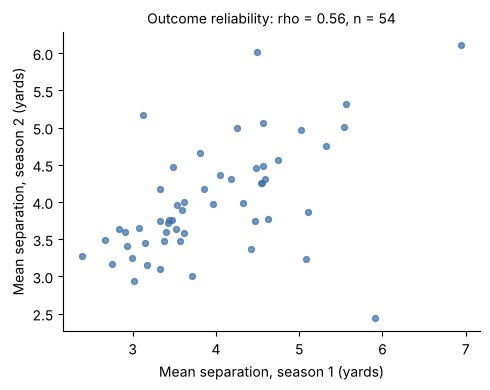

In [7]:
t2 = pp[(pp.target == 1) & pp.separation_at_pass_forward.notna()].merge(gm, on="game_id").merge(pl[["nfl_id","draft_year"]], on="nfl_id")
t2 = t2[t2.season_type == "REG"]
t2["yr"] = t2.season - t2.draft_year
t2 = t2[t2.yr.isin([0, 1])]
w = (t2.groupby(["nfl_id","yr"]).agg(n=("separation_at_pass_forward","size"),
     sep=("separation_at_pass_forward","mean")).reset_index()
     .pivot(index="nfl_id", columns="yr", values=["n","sep"]).dropna())
w.columns = ["n0","n1","s0","s1"]
w = w[(w.n0 >= 5) & (w.n1 >= 5)]
r_rel, p_rel = spearmanr(w.s0, w.s1)
print(f"Receivers with 5+ targets in both seasons: {len(w)} | year-one vs year-two rho={r_rel:.2f} (p={p_rel:.3f})")
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(w.s0, w.s1, s=18, alpha=0.7, color="#3b6ea5")
ax.set_xlabel("Mean separation, season 1 (yards)"); ax.set_ylabel("Mean separation, season 2 (yards)")
ax.set_title(f"Outcome reliability: rho = {r_rel:.2f}, n = {len(w)}", fontsize=10)
fig.tight_layout(); plt.show()

## 8. Summary
All results in one place. The writeup and `FINDINGS.md` report the same numbers.

In [8]:
print("RECEIVERS (slant and dagger, Spearman rho vs rookie separation)")
display(receiver_table)
print("\nDAGGER BREAK-DEFINITION CHECK")
display(pd.DataFrame(checks))
print("\nDEFENSIVE BACKS (vs completion rate allowed)")
display(pd.DataFrame(db_results))
print("\nOUTCOME RELIABILITY: rho =", round(r_rel, 2))

RECEIVERS (slant and dagger, Spearman rho vs rookie separation)


,test,min_targets,prospects,cut_angle_deg,speed_retained
0,"Slant, all routes",3,73,rho=-0.02 (p=0.87),rho=0.12 (p=0.33)
1,"Dagger, all routes",3,73,rho=0.08 (p=0.48),rho=0.30 (p=0.01)
2,"Slant, all routes",5,66,rho=-0.04 (p=0.77),rho=0.10 (p=0.43)
3,"Dagger, all routes",5,66,rho=0.02 (p=0.85),rho=0.32 (p=0.01)
4,"Slant, short routes",3,64,rho=-0.01 (p=0.93),rho=0.14 (p=0.26)
5,"Dagger, deep and intermediate",3,67,rho=-0.03 (p=0.82),rho=0.35 (p=0.00)



DAGGER BREAK-DEFINITION CHECK


,test,min_targets,prospects,speed_retained
0,"Dagger, braking break (alt rule)",3,73,rho=0.06 (p=0.61)
1,"Dagger, braking break (alt rule)",5,66,rho=0.14 (p=0.27)



DEFENSIVE BACKS (vs completion rate allowed)


,min_plays,DBs,cut_angle_deg,speed_retained,pre_speed
0,20,77,rho=0.19 (p=0.10),rho=0.07 (p=0.54),rho=-0.10 (p=0.39)
1,40,65,rho=0.18 (p=0.15),rho=0.04 (p=0.74),rho=-0.07 (p=0.57)



OUTCOME RELIABILITY: rho = 0.56


## Limitations
- Samples are small (roughly 20 to 80 players per test), so only moderate correlations are detectable.
- Combine drills are controlled movements; in-game separation depends on quarterback, play design and coverage.
- The defensive back outcome is an approximation (play result, not target-level attribution).
- Several tests were run; the dagger lead is reported as withdrawn for this reason.